<a href="https://colab.research.google.com/github/RohitSinghJethi/DATA-preprocessing/blob/main/data%20pre-processing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [20]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from urllib.request import urlretrieve
from pathlib import Path
import cv2

In [21]:
url = "https://storage.googleapis.com/tensorflow/tf-keras-datasets/mnist.npz"

file_path = Path("mnist.npz")

if not file_path.exists():
    urlretrieve(url, file_path)

print("Dataset downloaded successfully!")


Dataset downloaded successfully!


In [22]:
with np.load(file_path) as data:
    X_train = data["x_train"]
    y_train = data["y_train"]
    X_test = data["x_test"]
    y_test = data["y_test"]


print("Training images:", X_train.shape)
print("Training labels:", y_train.shape)
print("Testing images:", X_test.shape)
print("Testing labels:", y_test.shape)

Training images: (60000, 28, 28)
Training labels: (60000,)
Testing images: (10000, 28, 28)
Testing labels: (10000,)


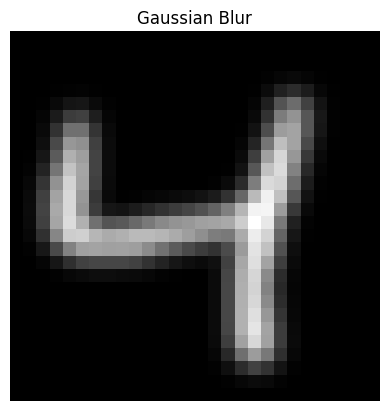

In [23]:
image = X_train[2]

gaussian = cv2.GaussianBlur(image, (5, 5), 1)

plt.imshow(gaussian, cmap="gray")
plt.title("Gaussian Blur")
plt.axis("off")
plt.show()

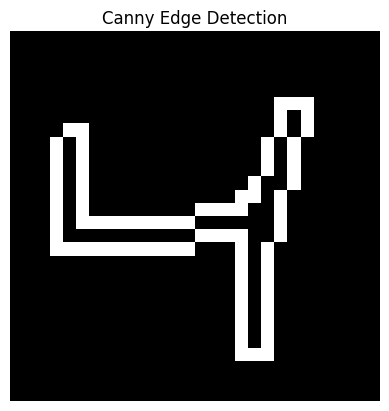

In [24]:

edges = cv2.Canny(image, 50, 150)

plt.imshow(edges, cmap="gray")
plt.title("Canny Edge Detection")
plt.axis("off")
plt.show()

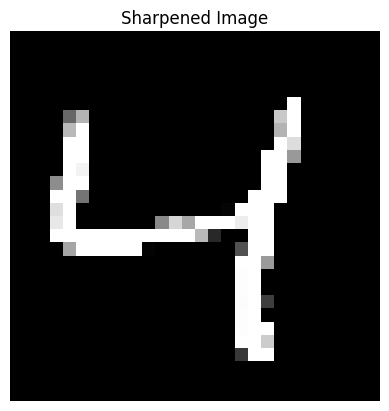

In [27]:
sharpen_kernel = np.array([
    [0, -1, 0],
    [-1, 5, -1],
    [0, -1, 0]
])

sharpened = cv2.filter2D(image, -1, sharpen_kernel)

plt.imshow(sharpened, cmap="gray")
plt.title("Sharpened Image")
plt.axis("off")
plt.show()

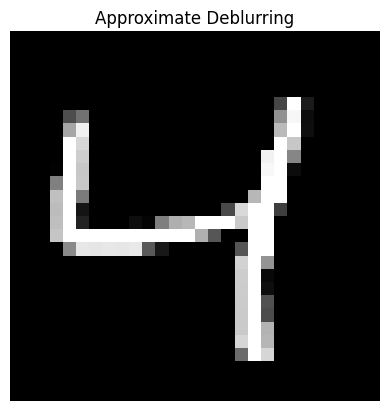

In [28]:
blurred = cv2.GaussianBlur(image, (5, 5), 1)

deblurred = cv2.addWeighted(
    image, 2.0,
    blurred, -1.0,
    0
)

plt.imshow(deblurred, cmap="gray")
plt.title("Approximate Deblurring")
plt.axis("off")
plt.show()

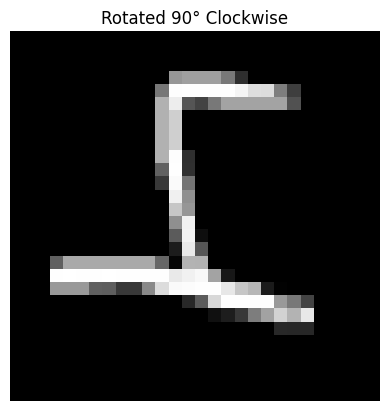

In [29]:


rotated = cv2.rotate(
    image,
    cv2.ROTATE_90_CLOCKWISE
)

plt.imshow(rotated, cmap="gray")
plt.title("Rotated 90° Clockwise")
plt.axis("off")
plt.show()


In [30]:
X_train_norm = X_train.astype(np.float32) / 255.0
X_test_norm = X_test.astype(np.float32) / 255.0

print("Minimum pixel:", X_train_norm.min())
print("Maximum pixel:", X_train_norm.max())
print("Data type:", X_train_norm.dtype)

Minimum pixel: 0.0
Maximum pixel: 1.0
Data type: float32


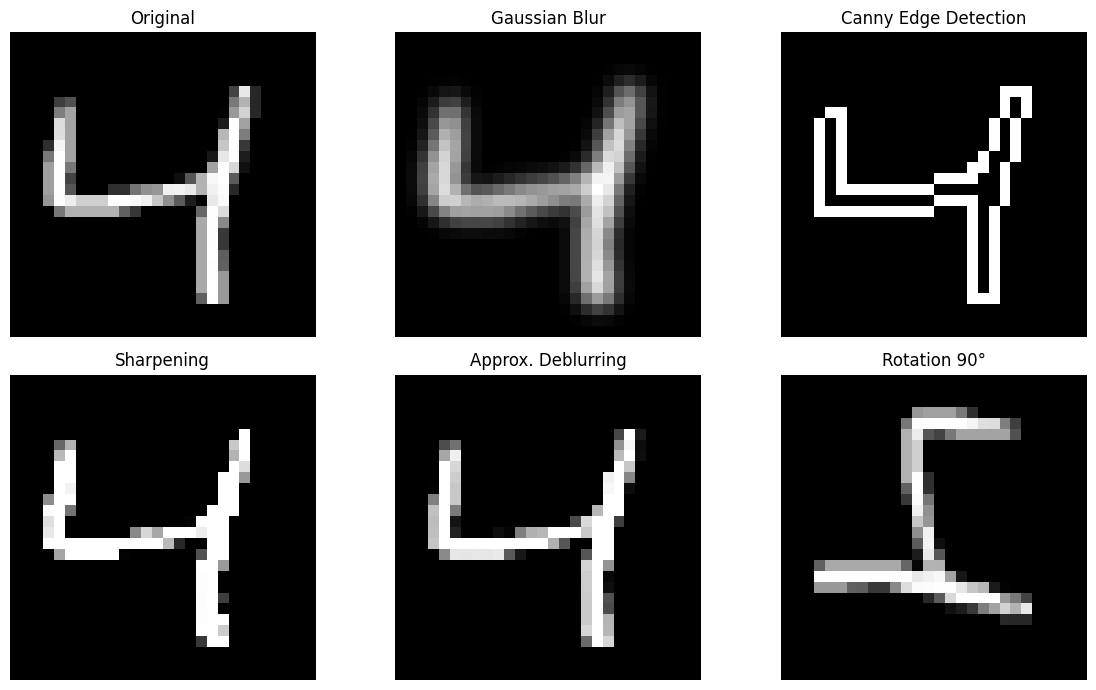

In [31]:
images = [image, gaussian, edges,sharpened, deblurred, rotated]

titles = ["Original", "Gaussian Blur", "Canny Edge Detection","Sharpening", "Approx. Deblurring", "Rotation 90°"]
plt.figure(figsize=(12, 7))
for i in range(len(images)):
    plt.subplot(2, 3, i + 1)
    plt.imshow(images[i], cmap="gray")
    plt.title(titles[i])
    plt.axis("off")

plt.tight_layout()
plt.show()